# Stock Risk Report

Parameterized single-stock report on `ohlc_hw_cleaned`. Returns, volatility, Sharpe and drawdown use **adjusted close** and daily **log returns**. Run directly or via `03_run_all_stocks.py` (papermill).

In [1]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # Database with ohlc_hw_cleaned

In [2]:
# Parameters
ticker = "IBM"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/vishal.jsoni/PersonalProjects/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Vishal_Soni/data/data.db"


In [3]:
import sqlite3
from contextlib import closing

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

## Data

In [4]:
query = """
    SELECT ts, open, high, low, close, adj_close, volume
    FROM ohlc_hw_cleaned
    WHERE ticker = ? AND ts BETWEEN ? AND ?
    ORDER BY ts
"""
with closing(sqlite3.connect(db_path)) as conn:
    df = pd.read_sql_query(query, conn, params=(ticker, start_date, end_date), parse_dates=["ts"]).set_index("ts")
    history_end = pd.Timestamp(conn.execute(
        "SELECT MAX(ts) FROM ohlc_hw_cleaned WHERE ticker = ?", (ticker,)).fetchone()[0])

if len(df) < 21:
    raise ValueError(f"{ticker}: {len(df)} prices between {start_date} and {end_date}; "
                     "at least 21 are needed for 20 daily returns.")

print(f"{ticker} from {start_date} to {end_date}: {len(df)} trading days")
print(f"Actual observations: {df.index[0]:%Y-%m-%d} to {df.index[-1]:%Y-%m-%d}")
if history_end < pd.Timestamp(end_date):
    print(f"Note: supplied history ends {history_end:%Y-%m-%d}; later dates are not extrapolated.")
display(df.head(), df.tail())

IBM from 2024-06-01 to 2024-11-30: 126 trading days
Actual observations: 2024-06-03 to 2024-11-29


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,166.54,166.78,163.53,165.28,162.57,2776100
2024-06-04,164.60,166.40,163.88,165.81,163.09,2594203
2024-06-05,166.41,167.79,165.78,167.38,164.63,3049400
2024-06-06,167.38,168.44,166.80,168.20,165.44,2207263
2024-06-07,168.18,171.31,168.06,170.01,167.22,3475500


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-11-22,223.35,227.20,220.89,222.97,222.97,5320740
2024-11-25,223.35,226.42,222.65,226.13,226.13,7189300
2024-11-26,226.73,228.98,225.51,228.83,228.83,4449543
2024-11-27,228.83,229.19,224.27,226.92,226.92,2995121
2024-11-29,227.75,230.36,227.19,227.41,227.41,2640300


## Risk Metrics

In [5]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns (the first value is NaN)."""
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility; NaN until a full window exists."""
    return returns.rolling(window).std() * np.sqrt(252)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak (fraction, <= 0)."""
    peak = prices.cummax()
    return (prices - peak) / peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio; NaN for fewer than 2 returns or zero volatility."""
    returns = returns.dropna()
    std = returns.std()
    if len(returns) < 2 or not std > 1e-12:
        return np.nan
    return (returns.mean() * 252 - risk_free_rate) / (std * np.sqrt(252))

In [6]:
df["log_return"] = calculate_returns(df["adj_close"])
df["volatility"] = calculate_volatility(df["log_return"])
df["drawdown"] = calculate_max_drawdown(df["adj_close"])
df["ma_50"] = df["adj_close"].rolling(50).mean()

returns = df["log_return"].dropna()
mean_vol = df["volatility"].mean()
sharpe = calculate_sharpe_ratio(returns)

print(f"Sharpe ratio: {sharpe:.2f}" if pd.notna(sharpe) else "Sharpe ratio: N/A")
print(f"Mean 20-day volatility: {mean_vol:.2%}")
print(f"Maximum drawdown: {df['drawdown'].min():.2%}")
if df["ma_50"].isna().all():
    print(f"50-day MA unavailable: only {len(df)} prices in the window.")
df[["adj_close", "log_return", "volatility", "drawdown", "ma_50"]].tail()

Sharpe ratio: 3.22
Mean 20-day volatility: 19.93%
Maximum drawdown: -12.90%


,adj_close,log_return,volatility,drawdown,ma_50
ts,,,,,
2024-11-22,222.97,0.002560,0.241515,-0.044769,218.0336
2024-11-25,226.13,0.014073,0.241623,-0.031231,218.2470
2024-11-26,228.83,0.011869,0.236457,-0.019664,218.5744
2024-11-27,226.92,-0.008382,0.212190,-0.027847,218.8476
2024-11-29,227.41,0.002157,0.212125,-0.025748,219.1514


## Visualization

Price segments are red when 20-day volatility is above its report mean, green at or below it, and gray during the warm-up (retrospective coloring). Rolling warm-up gaps are left empty.

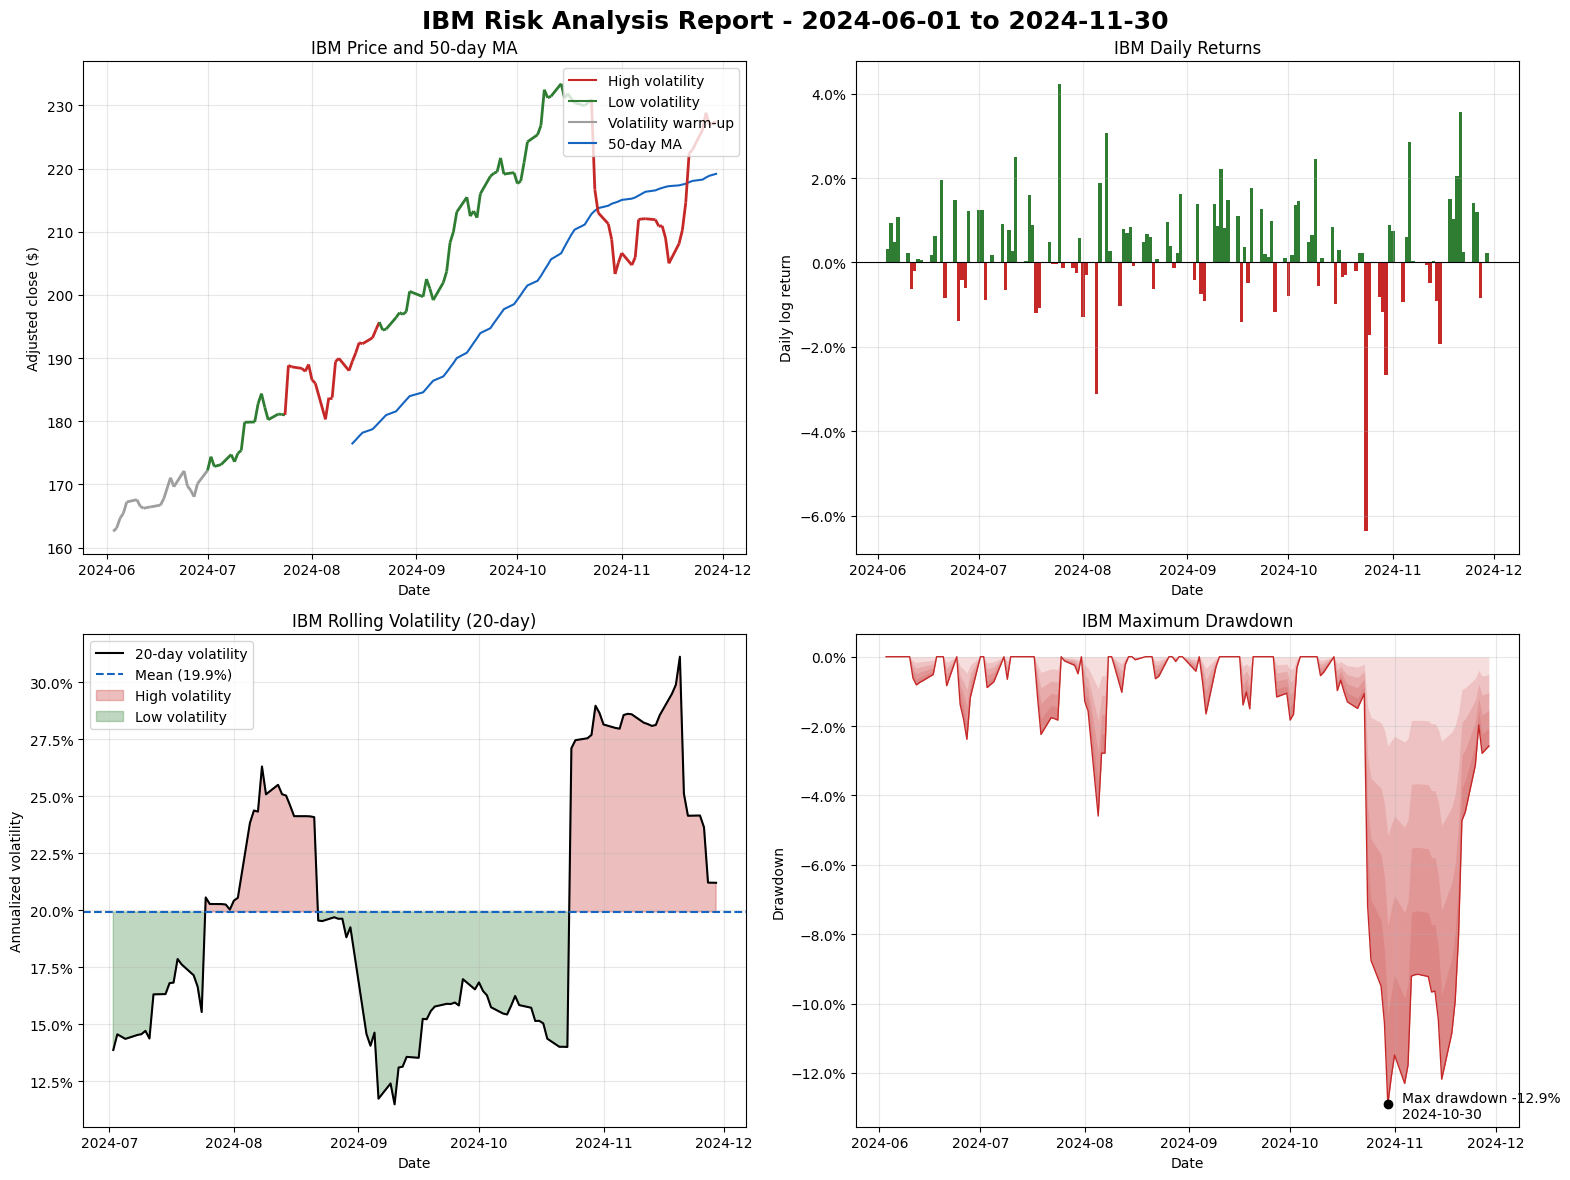

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
(ax_price, ax_ret), (ax_vol, ax_dd) = axes
UP, DOWN, NEUTRAL = "#2e7d32", "#c62828", "#9e9e9e"

# Price colored by volatility regime, with 50-day MA
ax_price.plot(df.index, df["ma_50"], color="#1565c0", linewidth=1.5, label="50-day MA")
x = ax_price.xaxis.convert_units(df.index.to_pydatetime())
points = np.column_stack([x, df["adj_close"]])
vol = df["volatility"].iloc[1:]
colors = np.where(vol.isna(), NEUTRAL, np.where(vol > mean_vol, DOWN, UP))
ax_price.add_collection(LineCollection(np.stack([points[:-1], points[1:]], axis=1), colors=colors, linewidth=2))
ax_price.autoscale_view()
ax_price.legend(handles=[Line2D([], [], color=DOWN, label="High volatility"),
                         Line2D([], [], color=UP, label="Low volatility"),
                         Line2D([], [], color=NEUTRAL, label="Volatility warm-up"),
                         Line2D([], [], color="#1565c0", label="50-day MA")])
ax_price.set(title=f"{ticker} Price and 50-day MA", xlabel="Date", ylabel="Adjusted close ($)")

# Daily returns
ax_ret.bar(df.index, df["log_return"], color=np.where(df["log_return"] >= 0, UP, DOWN), width=1)
ax_ret.axhline(0, color="black", linewidth=0.8)
ax_ret.yaxis.set_major_formatter(PercentFormatter(1))
ax_ret.set(title=f"{ticker} Daily Returns", xlabel="Date", ylabel="Daily log return")

# Rolling volatility with regime shading
ax_vol.plot(df.index, df["volatility"], color="black", linewidth=1.5, label="20-day volatility")
ax_vol.axhline(mean_vol, color="#1565c0", linestyle="--", label=f"Mean ({mean_vol:.1%})")
ax_vol.fill_between(df.index, df["volatility"], mean_vol, where=df["volatility"] > mean_vol,
                    color=DOWN, alpha=0.3, interpolate=True, label="High volatility")
ax_vol.fill_between(df.index, df["volatility"], mean_vol, where=df["volatility"] <= mean_vol,
                    color=UP, alpha=0.3, interpolate=True, label="Low volatility")
ax_vol.yaxis.set_major_formatter(PercentFormatter(1))
ax_vol.legend()
ax_vol.set(title=f"{ticker} Rolling Volatility (20-day)", xlabel="Date", ylabel="Annualized volatility")

# Drawdown: layered transparent fills give a red gradient
for depth in np.linspace(0, 0.8, 5):
    ax_dd.fill_between(df.index, df["drawdown"], df["drawdown"] * depth, color=DOWN, alpha=0.15, linewidth=0)
ax_dd.plot(df.index, df["drawdown"], color=DOWN, linewidth=1)
worst = df["drawdown"].idxmin()
ax_dd.scatter(worst, df.loc[worst, "drawdown"], color="black", zorder=3)
ax_dd.annotate(f"Max drawdown {df.loc[worst, 'drawdown']:.1%}\n{worst:%Y-%m-%d}",
               (worst, df.loc[worst, "drawdown"]), xytext=(10, -10), textcoords="offset points")
ax_dd.yaxis.set_major_formatter(PercentFormatter(1))
ax_dd.set(title=f"{ticker} Maximum Drawdown", xlabel="Date", ylabel="Drawdown")

for ax in axes.flat:
    ax.grid(alpha=0.3)
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=18, fontweight="bold")
fig.tight_layout()
plt.show()

## Summary Statistics

In [8]:
n = len(returns)
up, down = returns[returns > 0], returns[returns < 0]
stats = {
    "Total Return": df["adj_close"].iloc[-1] / df["adj_close"].iloc[0] - 1,
    "Annualized Return": np.expm1(returns.sum() * 252 / n),
    "Annualized Volatility": returns.std() * np.sqrt(252),
    "Sharpe Ratio": sharpe,
    "Maximum Drawdown": df["drawdown"].min(),
    "Best Day": returns.max(),
    "Worst Day": returns.min(),
    "Positive Days": len(up) / n,
    "Average Up Day": up.mean(),
    "Average Down Day": down.mean(),
}


def format_metric(name: str, value: float) -> str:
    """Display format: N/A for undefined, plain for Sharpe, unsigned or signed percent otherwise."""
    if pd.isna(value):
        return "N/A"
    if name == "Sharpe Ratio":
        return f"{value:.2f}"
    return f"{value:.2%}" if name in ("Annualized Volatility", "Positive Days") else f"{value:+.2%}"


summary = pd.DataFrame({"Metric": stats.keys(), "Value": [format_metric(k, v) for k, v in stats.items()]})
print(summary.to_string(index=False))

               Metric   Value
         Total Return +39.88%
    Annualized Return +96.73%
Annualized Volatility  20.42%
         Sharpe Ratio    3.22
     Maximum Drawdown -12.90%
             Best Day  +4.24%
            Worst Day  -6.37%
        Positive Days  63.20%
       Average Up Day  +0.95%
     Average Down Day  -0.92%


In [9]:
# Named outputs collected by 03_run_all_stocks.py
outputs = {
    "ticker": ticker,
    "first_date": f"{df.index[0]:%Y-%m-%d}",
    "last_date": f"{df.index[-1]:%Y-%m-%d}",
    "avg_daily_return": float(returns.mean()),
    "avg_volatility": float(mean_vol),
    "max_drawdown": float(stats["Maximum Drawdown"]),
    "sharpe_ratio": float(sharpe),
    "total_return": float(stats["Total Return"]),
}
for name, value in outputs.items():
    sb.glue(name, value)